# terrio, GDAL, rasterio and rioxarray side by side

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/opengeos/terrio/blob/main/docs/notebooks/comparison.ipynb)

The [quickstart](https://terrio.dev/notebooks/) workflow, written four ways: with [terrio](https://terrio.dev), with GDAL's Python bindings (`osgeo.gdal`), with [rasterio](https://rasterio.readthedocs.io) and with [rioxarray](https://corteva.github.io/rioxarray/), plus [GeoPandas](https://geopandas.org) and [pyproj](https://pyproj4.github.io/pyproj/) for the vector and coordinate steps where those are what rasterio users reach for. Each step checks that the libraries produce the same result and times each one.

The steps:

1. read the header and an overview of a USGS 3DEP elevation COG on Amazon S3, over HTTP;
2. write a full-resolution window of it to a GeoTIFF;
3. hillshade and slope;
4. reprojection to UTM;
5. NDVI from a Landsat 7 image;
6. the world's countries: filtered, reprojected and written as GeoPackage;
7. rasterizing the countries;
8. transforming a coordinate.

## Install

terrio's wheel needs only NumPy. rasterio's wheels bundle their own copy of GDAL. GDAL's Python bindings need a matching GDAL library, so they are usually installed with conda (`conda install -c conda-forge gdal`); Google Colab ships them preinstalled.

In [ ]:
%pip install -q terrio rasterio rioxarray geopandas matplotlib

In [2]:
import time
from contextlib import contextmanager

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyproj
import rasterio
import rasterio.features
import rasterio.warp
import rioxarray
import terrio
from osgeo import gdal, ogr, osr
from rasterio.windows import Window

gdal.UseExceptions()

pd.DataFrame(
    {
        "version": [
            terrio.__version__,
            gdal.__version__,
            rasterio.__version__,
            rioxarray.__version__,
            gpd.__version__,
            pyproj.__version__,
        ]
    },
    index=["terrio", "GDAL (osgeo)", "rasterio", "rioxarray", "geopandas", "pyproj"],
)

,version
terrio,0.7.0
GDAL (osgeo),3.12.2
rasterio,1.5.0
rioxarray,0.22.0
geopandas,1.1.4
pyproj,3.7.2


rasterio and the GDAL bindings each load their own GDAL library, possibly of different versions:

In [3]:
print("osgeo.gdal:", gdal.__version__, "  rasterio's GDAL:", rasterio.__gdal_version__)

osgeo.gdal: 3.12.2   rasterio's GDAL: 3.12.2


A small helper records how long each library takes for each step. Timings of the HTTP steps depend on the network and on what earlier cells have already cached, so read them as rough.

In [4]:
timings = {}


@contextmanager
def timed(step, library):
    """Record the wall-clock time of the block as `timings[step][library]`."""
    start = time.perf_counter()
    yield
    timings.setdefault(step, {})[library] = time.perf_counter() - start


def same(name, a, b, atol=0):
    """Print whether two arrays are equal, the largest difference, and NaNs present in only one."""
    a = np.asarray(a, dtype="float64")
    b = np.asarray(b, dtype="float64")
    if a.shape != b.shape:
        print(f"{name}: shapes differ, {a.shape} and {b.shape}")
        return
    nan_a, nan_b = np.isnan(a), np.isnan(b)
    nan_mismatch = np.count_nonzero(nan_a != nan_b)
    diff = np.abs(np.where(nan_a | nan_b, 0, a - b))
    worst = diff.max() if diff.size else 0
    if nan_mismatch:
        verdict = "DIFFER"
    else:
        verdict = "identical" if worst == 0 else ("within tolerance" if worst <= atol else "DIFFER")
    print(
        f"{name}: {verdict} (max |difference| = {worst:g}, {np.count_nonzero(diff > atol)} pixels over {atol:g}, "
        f"{nan_mismatch} pixels NaN in only one)"
    )

## 1. A cloud-optimized GeoTIFF, read in place

A 1 arc-second USGS 3DEP elevation tile (about 50 MB). Opening it fetches only its header; each library reads the tiles it needs with HTTP range requests. GDAL needs the `/vsicurl/` prefix; rasterio and rioxarray add it themselves.

In [5]:
url = "https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/1/TIFF/current/n40w106/USGS_1_n40w106.tif"
step = "open + smallest overview"

In [6]:
with timed(step, "terrio"):
    dem = terrio.open_raster(url, lazy=True)
    ov_terrio = dem.read(1, overview=len(dem.overviews) - 1)
print(dem.width, dem.height, dem.dtype, dem.crs, dem.overviews)

3612 3612 float32 EPSG:4269 [(1806, 1806), (903, 903), (451, 451)]


In [7]:
with timed(step, "GDAL"):
    ds = gdal.Open(f"/vsicurl/{url}")
    band = ds.GetRasterBand(1)
    ov_gdal = band.GetOverview(band.GetOverviewCount() - 1).ReadAsArray()
print(
    ds.RasterXSize,
    ds.RasterYSize,
    gdal.GetDataTypeName(band.DataType),
    ds.GetSpatialRef().GetAuthorityCode(None),
    [(band.GetOverview(i).XSize, band.GetOverview(i).YSize) for i in range(band.GetOverviewCount())],
)

3612 3612 Float32 4269 [(1806, 1806), (903, 903), (451, 451)]


In [8]:
with timed(step, "rasterio"):
    with rasterio.open(url) as src:
        factors = src.overviews(1)
        profile = src.profile
        smallest = (src.height // factors[-1], src.width // factors[-1])
        ov_rasterio = src.read(1, out_shape=smallest)
print(profile["width"], profile["height"], profile["dtype"], profile["crs"], factors)

3612 3612 float32 EPSG:4269 [2, 4, 8]


rasterio picks an overview from the requested output shape; rioxarray takes the overview's index:

In [9]:
with timed(step, "rioxarray"):
    ov_rxr = rioxarray.open_rasterio(url, overview_level=len(factors) - 1).sel(band=1).values
print(ov_rxr.shape)

(451, 451)


GDAL vs terrio: identical (max |difference| = 0, 0 pixels over 0, 0 pixels NaN in only one)
rasterio vs terrio: identical (max |difference| = 0, 0 pixels over 0, 0 pixels NaN in only one)
rioxarray vs terrio: identical (max |difference| = 0, 0 pixels over 0, 0 pixels NaN in only one)


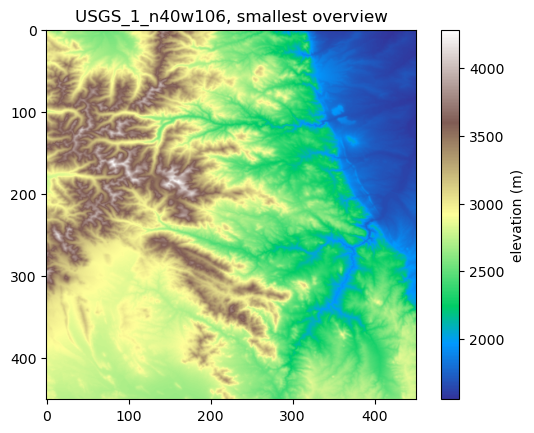

In [10]:
same("GDAL vs terrio", ov_gdal, ov_terrio)
same("rasterio vs terrio", ov_rasterio, ov_terrio)
same("rioxarray vs terrio", ov_rxr, ov_terrio)
plt.imshow(np.where(ov_terrio == dem.nodata, np.nan, ov_terrio), cmap="terrain")
plt.colorbar(label="elevation (m)")
plt.title("USGS_1_n40w106, smallest overview");

## 2. A full-resolution window to a GeoTIFF

A 1024 × 1024 window over the Front Range between Estes Park and Lyons, Colorado.

In [11]:
col, row, size = 2000, 1500, 1024
step = "window to GeoTIFF"

with timed(step, "terrio"):
    terrio.convert(url, "window_terrio.tif", srcwin=(col, row, size, size))

with timed(step, "GDAL"):
    gdal.Translate("window_gdal.tif", f"/vsicurl/{url}", srcWin=[col, row, size, size])

with timed(step, "rasterio"):
    with rasterio.open(url) as src:
        window = Window(col, row, size, size)
        data = src.read(window=window)
        profile = src.profile | {
            "width": size,
            "height": size,
            "transform": src.window_transform(window),
            "driver": "GTiff",
        }
    with rasterio.open("window_rasterio.tif", "w", **profile) as dst:
        dst.write(data)

with timed(step, "rioxarray"):
    da = rioxarray.open_rasterio(url)
    da.isel(x=slice(col, col + size), y=slice(row, row + size)).rio.to_raster("window_rioxarray.tif")

The four files hold the same pixels on the same grid:

In [12]:
window = terrio.open_raster("window_terrio.tif")
reference = window.read(1)
for library in ["gdal", "rasterio", "rioxarray"]:
    with rasterio.open(f"window_{library}.tif") as src:
        same(f"{library} vs terrio", src.read(1), reference)
        assert np.allclose(src.transform.to_gdal(), window.transform), library
print(window.transform)

gdal vs terrio: identical (max |difference| = 0, 0 pixels over 0, 0 pixels NaN in only one)
rasterio vs terrio: identical (max |difference| = 0, 0 pixels over 0, 0 pixels NaN in only one)
rioxarray vs terrio: identical (max |difference| = 0, 0 pixels over 0, 0 pixels NaN in only one)
(-105.44611111101045, 0.00027777777803598015, 0.0, 39.5850000003035, 0.0, -0.0002777777777870148)


## 3. Terrain analysis

`terrio.dem` is `gdaldem`, and `gdal.DEMProcessing` is its Python form. rasterio and rioxarray have no terrain functions: the usual route is NumPy (shown here for slope, Horn's method like GDAL) or a package such as [xarray-spatial](https://xarray-spatial.readthedocs.io).

In [13]:
step = "hillshade + slope"

with timed(step, "terrio"):
    shade_terrio = terrio.dem("window_terrio.tif", "hillshade", multidirectional=True).read(1)
    slope_terrio = terrio.dem("window_terrio.tif", "slope")
slope_nodata = slope_terrio.nodata
slope_terrio = slope_terrio.read(1)

with timed(step, "GDAL"):
    shade_gdal = gdal.DEMProcessing("", "window_gdal.tif", "hillshade", format="MEM", multiDirectional=True).ReadAsArray()
    slope_gdal = gdal.DEMProcessing("", "window_gdal.tif", "slope", format="MEM").ReadAsArray()

same("hillshade, GDAL vs terrio", shade_gdal, shade_terrio)
same("slope, GDAL vs terrio", slope_gdal, slope_terrio, atol=1e-4)

hillshade, GDAL vs terrio: identical (max |difference| = 0, 0 pixels over 0, 0 pixels NaN in only one)
slope, GDAL vs terrio: identical (max |difference| = 0, 0 pixels over 0.0001, 0 pixels NaN in only one)


With rasterio and NumPy, slope needs the pixel size in metres. The DEM is in degrees, so, as `gdaldem` does, convert them to metres on the CRS's ellipsoid at the window's centre latitude, then apply a 3 × 3 Horn kernel and leave the edges as nodata:

In [14]:
def horn_slope(z, xres, yres, nodata):
    """Slope in degrees with Horn's method; the edges and windows touching nodata are nodata."""
    z = z.astype("float64")
    a, b, c = z[:-2, :-2], z[:-2, 1:-1], z[:-2, 2:]
    d, f = z[1:-1, :-2], z[1:-1, 2:]
    g, h, i = z[2:, :-2], z[2:, 1:-1], z[2:, 2:]
    dzdx = ((c + 2 * f + i) - (a + 2 * d + g)) / (8 * xres)
    dzdy = ((g + 2 * h + i) - (a + 2 * b + c)) / (8 * yres)
    out = np.full(z.shape, nodata, dtype="float32")
    out[1:-1, 1:-1] = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))
    return out


with timed(step, "rasterio + NumPy"):
    with rasterio.open("window_rasterio.tif") as src:
        z = src.read(1)
        xres, yres = src.res
        metres_per_degree = np.radians(pyproj.CRS(src.crs.to_wkt()).ellipsoid.semi_major_metre)
        centre_lat = (src.bounds.top + src.bounds.bottom) / 2
    slope_numpy = horn_slope(
        z,
        xres * metres_per_degree * np.cos(np.radians(centre_lat)),
        yres * metres_per_degree,
        slope_nodata,
    )

same("slope, NumPy vs terrio", slope_numpy, slope_terrio, atol=1e-3)

slope, NumPy vs terrio: within tolerance (max |difference| = 0.000677586, 0 pixels over 0.001, 0 pixels NaN in only one)


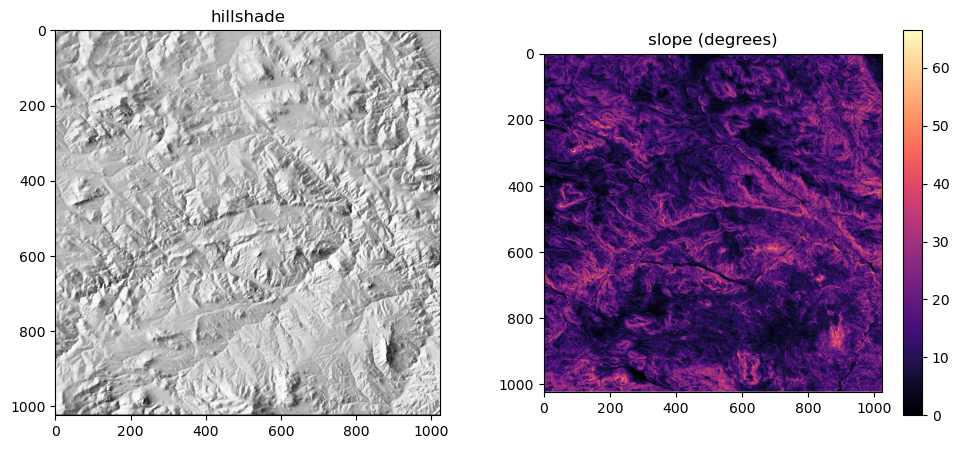

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(shade_terrio, cmap="gray")
axes[0].set_title("hillshade")
im = axes[1].imshow(np.ma.masked_equal(slope_terrio, slope_nodata), cmap="magma")
axes[1].set_title("slope (degrees)")
fig.colorbar(im, ax=axes[1]);

## 4. Reprojection

To UTM zone 13N at 30 m with bilinear resampling. terrio and GDAL take the target CRS and resolution and choose the output grid; rasterio needs the grid computed first with `calculate_default_transform`, and rioxarray calls rasterio.

In [16]:
step = "reproject to UTM"

with timed(step, "terrio"):
    utm_terrio = terrio.warp("window_terrio.tif", "utm_terrio.tif", t_srs="EPSG:32613", tr=(30, 30), resampling="bilinear")

with timed(step, "GDAL"):
    gdal.Warp("utm_gdal.tif", "window_gdal.tif", dstSRS="EPSG:32613", xRes=30, yRes=30, resampleAlg="bilinear")

with timed(step, "rasterio"):
    with rasterio.open("window_rasterio.tif") as src:
        transform, width, height = rasterio.warp.calculate_default_transform(
            src.crs, "EPSG:32613", src.width, src.height, *src.bounds, resolution=30
        )
        profile = src.profile | {"crs": "EPSG:32613", "transform": transform, "width": width, "height": height}
        with rasterio.open("utm_rasterio.tif", "w", **profile) as dst:
            rasterio.warp.reproject(
                rasterio.band(src, 1),
                rasterio.band(dst, 1),
                resampling=rasterio.warp.Resampling.bilinear,
            )

with timed(step, "rioxarray"):
    rioxarray.open_rasterio("window_rioxarray.tif").rio.reproject(
        "EPSG:32613", resolution=30, resampling=rasterio.warp.Resampling.bilinear
    ).rio.to_raster("utm_rioxarray.tif")

The output grids, and the pixels where two outputs share a grid:

In [17]:
print(f"{'terrio':10}", utm_terrio.width, utm_terrio.height, utm_terrio.transform)
outputs = {}
for library in ["gdal", "rasterio", "rioxarray"]:
    with rasterio.open(f"utm_{library}.tif") as src:
        outputs[library] = src.read(1)
        print(f"{library:10}", src.width, src.height, src.transform.to_gdal())
same("GDAL vs terrio", outputs["gdal"], utm_terrio.read(1), atol=1e-3)
same("rioxarray vs rasterio", outputs["rioxarray"], outputs["rasterio"], atol=1e-3)

terrio     819 1055 (461534.4079792774, 30.0, 0.0, 4381793.0771725755, 0.0, -30.0)
gdal       819 1055 (461534.4079792774, 30.0, 0.0, 4381793.0771725755, 0.0, -30.0)
rasterio   820 1055 (461534.4079792774, 30.0, 0.0, 4381793.0771725755, 0.0, -30.0)
rioxarray  820 1055 (461534.4079792774, 30.0, 0.0, 4381793.0771725755, 0.0, -30.0)
GDAL vs terrio: identical (max |difference| = 0, 0 pixels over 0.001, 0 pixels NaN in only one)
rioxarray vs rasterio: within tolerance (max |difference| = 0.000244141, 0 pixels over 0.001, 0 pixels NaN in only one)


terrio follows `gdalwarp` and computes the same grid as GDAL. rasterio's `calculate_default_transform` sizes the grid with its own method, so its output covers a slightly different extent and is not compared pixel by pixel with the others.

## 5. A multispectral image and raster algebra

NDVI from a Landsat 7 scene of San Francisco Bay (bands 1 to 3 are near infrared, red and green). `terrio.calc` is `gdal_calc.py`; with GDAL, rasterio and rioxarray the arithmetic is NumPy or xarray on the arrays they read.

The image declares 0 as nodata, but in 8 bits the red band is 0 over dense vegetation, so the nodata value is ignored. Water, 0 in both bands, divides 0 by 0 and is left as NaN.

GDAL vs terrio: identical (max |difference| = 0, 0 pixels over 1e-06, 0 pixels NaN in only one)
rasterio vs terrio: identical (max |difference| = 0, 0 pixels over 1e-06, 0 pixels NaN in only one)
rioxarray vs terrio: identical (max |difference| = 0, 0 pixels over 1e-06, 0 pixels NaN in only one)


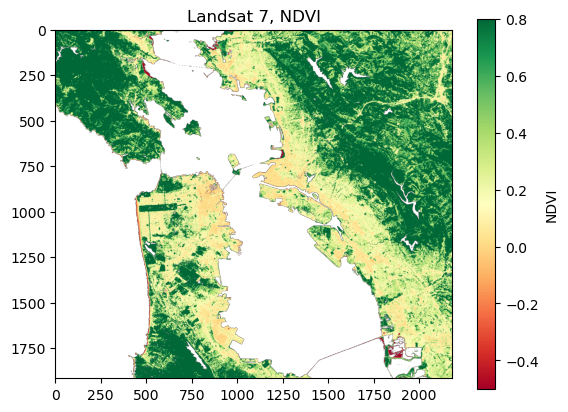

In [18]:
landsat_url = "https://raw.githubusercontent.com/opengeos/data/main/raster/landsat7.tif"
terrio.convert(landsat_url, "landsat7.tif")
step = "NDVI"

with timed(step, "terrio"):
    ndvi_terrio = terrio.calc(
        "(A - B * 1.0) / (A + B * 1.0)",
        A="landsat7.tif",
        A_band=1,
        B="landsat7.tif",
        B_band=2,
        type="Float32",
        hide_nodata=True,
    ).read(1)

with np.errstate(divide="ignore", invalid="ignore"):
    with timed(step, "GDAL"):
        ds = gdal.Open("landsat7.tif")
        nir = ds.GetRasterBand(1).ReadAsArray().astype("float32")
        red = ds.GetRasterBand(2).ReadAsArray().astype("float32")
        ndvi_gdal = (nir - red) / (nir + red)

    with timed(step, "rasterio"):
        with rasterio.open("landsat7.tif") as src:
            nir, red = src.read([1, 2]).astype("float32")
        ndvi_rasterio = (nir - red) / (nir + red)

    with timed(step, "rioxarray"):
        image = rioxarray.open_rasterio("landsat7.tif").astype("float32")
        nir, red = image.sel(band=1), image.sel(band=2)
        ndvi_rxr = ((nir - red) / (nir + red)).values

same("GDAL vs terrio", ndvi_gdal, ndvi_terrio, atol=1e-6)
same("rasterio vs terrio", ndvi_rasterio, ndvi_terrio, atol=1e-6)
same("rioxarray vs terrio", ndvi_rxr, ndvi_terrio, atol=1e-6)
plt.imshow(ndvi_terrio, cmap="RdYlGn", vmin=-0.5, vmax=0.8)
plt.colorbar(label="NDVI")
plt.title("Landsat 7, NDVI");

## 6. Vector data

The world's countries as GeoJSON, read from a URL, filtered with an attribute query, reprojected to Web Mercator and written as GeoPackage. GDAL's vector API is OGR, here through `gdal.VectorTranslate` (`ogr2ogr`); rasterio has no vector I/O, and its users reach for GeoPandas.

In [19]:
countries_url = "https://raw.githubusercontent.com/opengeos/data/main/world/countries.geojson"
terrio.convert(countries_url, "countries.geojson")
step = "filter + reproject + GeoPackage"

with timed(step, "terrio"):
    terrio.convert("countries.geojson", "united_terrio.gpkg", where="name LIKE 'United%'", t_srs="EPSG:3857")

with timed(step, "GDAL"):
    gdal.VectorTranslate("united_gdal.gpkg", "countries.geojson", where="name LIKE 'United%'", dstSRS="EPSG:3857")

with timed(step, "GeoPandas"):
    gdf = gpd.read_file("countries.geojson")
    gdf[gdf["name"].str.startswith("United")].to_crs("EPSG:3857").to_file("united_geopandas.gpkg")

In [20]:
for library in ["terrio", "gdal", "geopandas"]:
    result = gpd.read_file(f"united_{library}.gpkg")
    print(f"{library:10}", result.crs, sorted(result["name"]), [round(v) for v in result.total_bounds])

terrio     EPSG:3857 ['United Arab Emirates', 'United Kingdom', 'United Republic of Tanzania', 'United States of America'] [-19123699, -1313966, 6278068, 11525724]
gdal       EPSG:3857 ['United Arab Emirates', 'United Kingdom', 'United Republic of Tanzania', 'United States of America'] [-19123699, -1313966, 6278068, 11525724]
geopandas  EPSG:3857 ['United Arab Emirates', 'United Kingdom', 'United Republic of Tanzania', 'United States of America'] [-19123699, -1313966, 6278068, 11525724]


## 7. Rasterize

Burn the countries into a 0.5° grid of bytes. rasterio rasterizes shapes such as GeoPandas geometries onto a grid you define.

In [21]:
step = "rasterize"

with timed(step, "terrio"):
    mask_terrio = terrio.rasterize("countries.geojson", burn=1, tr=(0.5, 0.5), ot="Byte", init=0)
print(mask_terrio.width, mask_terrio.height, mask_terrio.transform)

with timed(step, "GDAL"):
    mask_gdal = gdal.Rasterize("", "countries.geojson", format="MEM", burnValues=[1], xRes=0.5, yRes=0.5, outputType=gdal.GDT_Byte, initValues=[0])
print(mask_gdal.RasterXSize, mask_gdal.RasterYSize, mask_gdal.GetGeoTransform())
mask_gdal = mask_gdal.ReadAsArray()

721 280 (-180.25, 0.5, 0.0, 83.89513, 0.0, -0.5)
721 280 (-180.25, 0.5, 0.0, 83.89513, 0.0, -0.5)


rasterio needs the grid: here the one terrio and GDAL derived from the layer's extent.

GDAL vs terrio: identical (max |difference| = 0, 0 pixels over 0, 0 pixels NaN in only one)
rasterio vs terrio: identical (max |difference| = 0, 0 pixels over 0, 0 pixels NaN in only one)


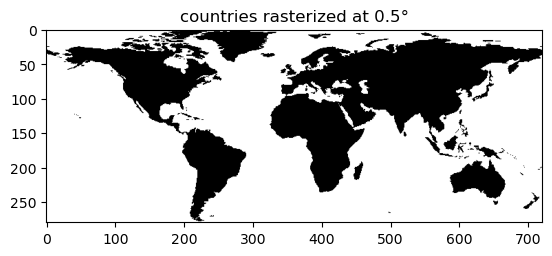

In [22]:
with timed(step, "rasterio + GeoPandas"):
    gdf = gpd.read_file("countries.geojson")
    mask_rasterio = rasterio.features.rasterize(
        ((geometry, 1) for geometry in gdf.geometry),
        out_shape=(mask_terrio.height, mask_terrio.width),
        transform=rasterio.Affine.from_gdal(*mask_terrio.transform),
        fill=0,
        dtype="uint8",
    )

same("GDAL vs terrio", mask_gdal, mask_terrio.read(1))
same("rasterio vs terrio", mask_rasterio, mask_terrio.read(1))
plt.imshow(mask_terrio.read(1), cmap="Greys")
plt.title("countries rasterized at 0.5°");

## 8. Coordinates

Boulder, Colorado from longitude and latitude to UTM zone 13N. GDAL's OSR takes latitude first for EPSG:4326 unless told to use the traditional GIS order; pyproj's `always_xy` does the same.

In [23]:
lon, lat = -105.2705, 40.015
step = "transform a point"

with timed(step, "terrio"):
    xs, ys = terrio.transform_points([lon], [lat], "EPSG:4326", "EPSG:32613")
print(f"{'terrio':10}", xs[0], ys[0])

with timed(step, "GDAL"):
    source, target = osr.SpatialReference(), osr.SpatialReference()
    source.ImportFromEPSG(4326)
    target.ImportFromEPSG(32613)
    source.SetAxisMappingStrategy(osr.OAMS_TRADITIONAL_GIS_ORDER)
    x, y, _ = osr.CoordinateTransformation(source, target).TransformPoint(lon, lat)
print(f"{'GDAL':10}", x, y)

with timed(step, "rasterio"):
    (x,), (y,) = rasterio.warp.transform("EPSG:4326", "EPSG:32613", [lon], [lat])
print(f"{'rasterio':10}", x, y)

with timed(step, "pyproj"):
    x, y = pyproj.Transformer.from_crs("EPSG:4326", "EPSG:32613", always_xy=True).transform(lon, lat)
print(f"{'pyproj':10}", x, y)

terrio     476915.239344975 4429457.112618952
GDAL       476915.239344975 4429457.112618952
rasterio   476915.239344975 4429457.112618952
pyproj     476915.239344975 4429457.112618952


## Timings

Seconds per step, from the runs above. Each library ran once, after earlier cells had opened the same files, so this is a rough comparison rather than a benchmark: see [terrio's benchmarks](https://terrio.dev/benchmarks/) for repeated measurements.

In [24]:
columns = ["terrio", "GDAL", "rasterio", "rioxarray", "rasterio + NumPy", "GeoPandas", "rasterio + GeoPandas", "pyproj"]
pd.DataFrame(timings).T[columns].round(3).fillna("")

,terrio,GDAL,rasterio,rioxarray,rasterio + NumPy,GeoPandas,rasterio + GeoPandas,pyproj
open + smallest overview,0.860,1.451,0.166,2.826,,,,
window to GeoTIFF,2.743,1.188,1.732,1.629,,,,
hillshade + slope,0.015,0.035,,,0.046,,,
reproject to UTM,0.346,0.118,0.137,0.089,,,,
NDVI,0.094,0.018,0.017,0.027,,,,
filter + reproject + GeoPackage,0.005,0.014,,,,0.02,,
rasterize,0.004,0.008,,,,,0.022,
transform a point,0.000,0.000,0.0,,,,,0.001


## Next

- [terrio's Python API](https://terrio.dev/python/), and the [quickstart](https://github.com/opengeos/terrio/blob/main/docs/notebooks/quickstart.ipynb) this notebook follows
- [`terrio.rasterio`](https://terrio.dev/rasterio/) and [`terrio.xarray`](https://terrio.dev/xarray/): rasterio's and rioxarray's APIs on terrio
- [GDAL conformance](https://terrio.dev/conformance/): how terrio's results are compared with GDAL's